# 01 · Data overview

MILK10k pairs every lesion with a dermoscopic image, a clinical close-up and a few metadata fields, labelled with one
of 11 diagnoses. MEL, BCC, SCCKA and MAL_OTH count as malignant; AKIEC counts as benign. Before modelling we check
what the data contain and how the fixed folds are built. The data come from the ISIC Archive under CC BY-NC 4.0,
with attribution to the MILK study team (`data/README.md`).

_This model was developed for a research competition and is not a medical device._

In [1]:
# Setup: every path comes from configs/final.yaml (milk10k.config); nothing here downloads data.
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RELEASE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(RELEASE / "src") not in sys.path:
    sys.path.insert(0, str(RELEASE / "src"))  # works without `pip install -e .`
from milk10k.config import load_config
from milk10k.metrics import CLASSES, MALIGNANT

cfg = load_config()
DATA = cfg["paths"]["data_dir"]  # prepared MILK10k (data/README.md); override with MILK10K_DATA_DIR

# "data:<file>" = under DATA; anything else is relative to the release root.
INPUTS = {
    "train_meta": "data:train_metadata.csv",
    "test_meta": "data:test_metadata.csv",
    "sample_sub": "data:sample_submission.csv",
    "folds": "data/folds.csv"
}
OUTPUTS = {
    "table_columns": "results/tables/01_column_summary.csv",
    "table_classes": "results/tables/01_class_counts.csv",
    "table_fold_counts": "results/tables/01_fold_class_counts.csv",
    "table_tone": "results/tables/01_tone_codes.csv",
    "image_sizes": "results/tables/01_image_sizes.csv",
    "fig_classes": "results/figures/01_class_distribution.png",
    "fig_folds": "results/figures/01_fold_class_counts.png"
}


def inp(key):
    v = INPUTS[key]
    return DATA / v[5:] if v.startswith("data:") else RELEASE / v


def out(key):
    p = RELEASE / OUTPUTS[key]
    p.parent.mkdir(parents=True, exist_ok=True)
    return p


def savefig(key):
    plt.tight_layout()
    plt.savefig(out(key), dpi=120)
    plt.show()


missing = [k for k in INPUTS if not inp(k).exists()]
import os  # noqa: E402
print("data dir from:", "MILK10K_DATA_DIR" if os.environ.get("MILK10K_DATA_DIR") else "configs/final.yaml")
print("checkpoints from:", "MILK10K_CHECKPOINT_DIR" if os.environ.get("MILK10K_CHECKPOINT_DIR") else "configs/final.yaml")
print("missing inputs:", missing or "none")

data dir from: MILK10K_DATA_DIR
checkpoints from: configs/final.yaml
missing inputs: none


## 1. Getting the data
`data/README.md` explains how to download the six release files. The next cell would rebuild the per-lesion layout
from them. It stays off (`PREPARE_DATA = False`) because it rewrites `data/raw/`; we work from a copy that is already
prepared, pointed to by `MILK10K_DATA_DIR`.

In [2]:
PREPARE_DATA = False
if PREPARE_DATA:
    import os
    import subprocess
    env = {**os.environ, "PYTHONPATH": str(RELEASE / "src")}
    subprocess.run([sys.executable, "-m", "milk10k.data_prep", "--source", str(cfg["paths"]["source_dir"]),
                    "--out", str(DATA)], check=True, env=env)
assert inp("train_meta").is_file(), f"prepared data not found under {DATA}: see data/README.md"

## 2. Tables and columns
What does one row look like, and what is missing? The test table has no labels: the official test labels are not public.

In [3]:
train = pd.read_csv(inp("train_meta"))
test = pd.read_csv(inp("test_meta"))
print(f"train lesions: {len(train):,} | test lesions: {len(test):,}")


def column_summary(df, split):
    return pd.DataFrame({"split": split, "dtype": df.dtypes.astype(str),
                         "missing_pct": df.isna().mean().mul(100).round(2), "n_unique": df.nunique()})


summary = pd.concat([column_summary(train, "train"), column_summary(test, "test")]).rename_axis("column").reset_index()
summary.to_csv(out("table_columns"), index=False)
summary

train lesions: 5,240 | test lesions: 479


,column,split,dtype,missing_pct,n_unique
0,isic_id,train,str,0.00,5240
1,lesion_id,train,str,0.00,5240
2,patient_id,train,str,0.00,5240
3,derm_image_path,train,str,0.00,5240
4,clinical_image_path,train,str,0.00,5240
5,clinical_available,train,int64,0.00,1
6,age_approx,train,float64,0.38,17
7,sex,train,str,0.00,2
8,anatomical_site_general,train,str,0.59,7
9,fitzpatrick_type,train,int64,0.00,6


There are 5,240 labelled lesions and 479 test lesions. Every lesion has both images (`clinical_available` is constant),
and the metadata are nearly complete: age is missing for 0.38% of lesions and site for 0.59%.

## 3. Diagnostic classes
How balanced are the eleven classes?

malignant rate: 0.659


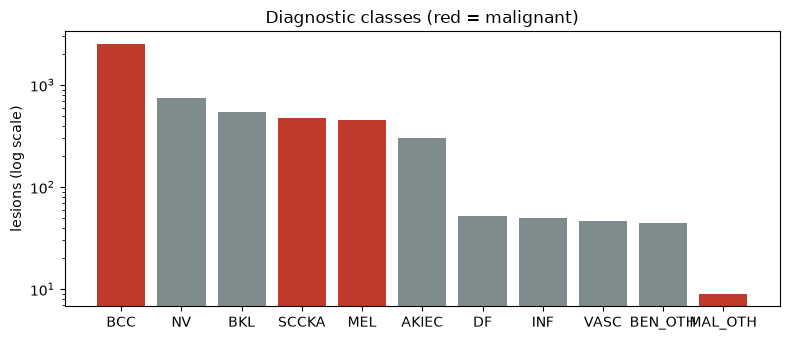

,lesions,share_pct,malignant
diagnostic_class_11,,,
BCC,2522,48.13,True
NV,746,14.24,False
BKL,544,10.38,False
SCCKA,473,9.03,True
MEL,450,8.59,True
AKIEC,303,5.78,False
DF,52,0.99,False
INF,50,0.95,False
VASC,47,0.90,False


In [4]:
counts = train.diagnostic_class_11.value_counts().reindex(CLASSES).fillna(0).astype(int)
classes = pd.DataFrame({"lesions": counts, "share_pct": (100 * counts / len(train)).round(2),
                        "malignant": [c in MALIGNANT for c in CLASSES]}).sort_values("lesions", ascending=False)
classes.to_csv(out("table_classes"))
print(f"malignant rate: {train.target_binary.mean():.3f}")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(classes.index, classes.lesions, color=["#c0392b" if m else "#7f8c8d" for m in classes.malignant])
ax.set_yscale("log")
ax.set_ylabel("lesions (log scale)")
ax.set_title("Diagnostic classes (red = malignant)")
savefig("fig_classes")
classes

BCC alone is 48% of all lesions, and malignancy is the majority (65.9%). The tail is extreme: MAL_OTH has 9 lesions,
and four benign classes have fewer than 60 each. Macro-AUC weights every class equally, so these rare classes count
as much as BCC.

## 4. Fixed folds
All experiments share one 5-fold split, stratified by diagnosis and grouped by `patient_id`. Can we trust it to keep
each patient's lesions in one fold?

patient_id == lesion_id for every lesion: True


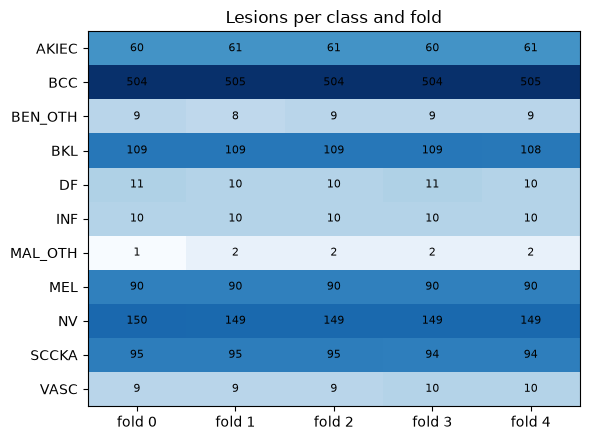

malignant rate per fold: {0: 0.658, 1: 0.66, 2: 0.659, 3: 0.658, 4: 0.659}


In [5]:
folds = pd.read_csv(inp("folds"))
assert folds.isic_id.is_unique and set(folds.isic_id) == set(train.isic_id), "folds.csv must cover every lesion once"
assert folds.groupby("patient_id").fold.nunique().max() == 1, "a group spans folds"
print("patient_id == lesion_id for every lesion:", bool((train.patient_id == train.lesion_id).all()))
tf = train.merge(folds[["isic_id", "fold"]], on="isic_id", validate="1:1")
per_fold = pd.crosstab(tf.diagnostic_class_11, tf.fold).reindex(CLASSES)
per_fold.to_csv(out("table_fold_counts"))
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.imshow(np.log1p(per_fold.to_numpy()), cmap="Blues", aspect="auto")
for (i, j), v in np.ndenumerate(per_fold.to_numpy()):
    ax.text(j, i, int(v), ha="center", va="center", fontsize=8)
ax.set_xticks(range(per_fold.shape[1]), [f"fold {k}" for k in per_fold.columns])
ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set_title("Lesions per class and fold")
savefig("fig_folds")
print("malignant rate per fold:", tf.groupby("fold").target_binary.mean().round(3).to_dict())

Not fully. The release has no patient identifier, so `patient_id` equals `lesion_id` for every lesion, and two lesions of
the same person can sit in different folds. Cross-validated scores are therefore somewhat optimistic. Otherwise the folds
are well balanced: the malignant rate is 0.658–0.660 in every fold.

## 5. Skin-tone codes
The fairness term compares pAUC80 across skin-tone groups, so how large are they? `fitzpatrick_type` is
`skin_tone_class + 1`. We could not verify whether the source scale runs from light to dark or the reverse, so we name
the groups by their numeric codes.

In [6]:
code_ = train.fitzpatrick_type.astype("Int64").astype(str).replace("<NA>", "missing")
by_code = pd.crosstab(code_, train.target_binary).rename(columns={0: "benign", 1: "malignant"})
group = train.fitzpatrick_type.map({1: "codes 1-2", 2: "codes 1-2", 3: "codes 3-4", 4: "codes 3-4",
                                    5: "codes 5-6", 6: "codes 5-6"}).fillna("missing")
by_group = pd.crosstab(group, train.target_binary).rename(columns={0: "benign", 1: "malignant"})
by_group["eligible_for_fairgap"] = (by_group.benign >= 10) & (by_group.malignant >= 10)
by_group.to_csv(out("table_tone"))
display(by_code)
by_group

target_binary,benign,malignant
fitzpatrick_type,,
1,5,1
2,68,37
3,300,206
4,949,2225
5,345,721
6,119,264


target_binary,benign,malignant,eligible_for_fairgap
fitzpatrick_type,,,
codes 1-2,73,38,True
codes 3-4,1249,2431,True
codes 5-6,464,985,True


Codes 1–2 hold only 111 lesions (38 malignant, 73 benign), against 3,680 and 1,449 in the other two groups. The small
group clears the threshold of 10 malignant and 10 benign lesions on the pooled data, but with so few lesions FairGap
will be noisy.

## 6. Image inventory
Do all image paths resolve, and how varied are the image sizes? Sizes are read from the file headers.

In [7]:
from PIL import Image


def image_sizes(df, split):
    rows = []
    for col, modality in (("derm_image_path", "derm"), ("clinical_image_path", "clinical")):
        for rel in df[col].dropna():
            if not rel:
                continue
            with Image.open(DATA / rel) as im:  # header only
                rows.append({"split": split, "modality": modality, "path": rel, "width": im.width, "height": im.height})
    return pd.DataFrame(rows)


sizes = pd.concat([image_sizes(train, "train"), image_sizes(test, "test")], ignore_index=True)
sizes.to_csv(out("image_sizes"), index=False)
print(f"images found: {len(sizes):,} (train+test lesions x 2 = {2 * (len(train) + len(test)):,})")
sizes.assign(size=sizes.width.astype(str) + "x" + sizes.height.astype(str)).groupby(["split", "modality"])["size"] \
    .value_counts().groupby(level=[0, 1]).head(3).rename("images").reset_index()

images found: 11,438 (train+test lesions x 2 = 11,438)


,split,modality,size,images
0,test,clinical,600x450,479
1,test,derm,600x450,479
2,train,clinical,600x450,5240
3,train,derm,600x450,5240


All 11,438 images are present, and every one of them is 600×450.

## Takeaways
- Malignancy is the majority class, so the binary difficulty lies in the high-sensitivity region that pAUC80 measures.
- The tail classes are tiny, so their AUCs will be unstable.
- The folds cannot separate patients, and the code 1–2 group is small. Both make the cross-validated numbers optimistic and FairGap noisy.

Next, notebook 02 explores the metadata, the images and where the final model still fails.